## Sprint 3 — Performance Personas (K-Means Clustering)

Groups students into qualitative "performance persona" clusters (e.g. *consistently strong*, *quietly disengaged*)
to sit **alongside** the risk score from `model_training_uci.ipynb` /
`model_training_oulad.ipynb` — not to replace it.

### Why bother clustering if we already have a risk score?

A risk score answers *"how likely is this student to fail/withdraw?"*. It doesn't
answer *"why?"*, and two students can land on the exact same risk score for
completely different reasons:

- A student who's **erratic but capable** — strong grades some periods, weak
  others — needs a very different conversation than
- A student who's **quietly disengaged** — steady low effort, no dramatic dips —
  even if their model-predicted risk score comes out identical.

Clustering doesn't predict anything; it just groups students by *shape of
behavior* using the same features the risk model already has. The persona label
is context an advisor reads next to the risk score, not a second opinion on it.

### What this notebook does, in order (run once for UCI, once for OULAD)
1. Load the feature matrix + risk scores already built
2. **`find_optimal_k()`** — elbow method + silhouette score, to justify how many
   clusters to use instead of picking a number arbitrarily
3. **`assign_personas()`** — fit K-Means with the chosen k, attach cluster labels
4. **Hand-label each cluster** by inspecting its actual centroid values — *not* by
   trusting a fixed `{0: "consistently_strong", 1: ...}` dictionary (see the
   Section 3 note on why that's fragile)
5. Merge personas with risk scores and visualize the combined picture
6. Save the enriched table for the dashboard

Repeated for both UCI and OULAD in their own sections below — same method, two
independent clusterings, since (per the plan) these are separate populations.

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Prevent Joblib/Loky from warning on Windows when it cannot detect physical cores.

# number of physical cores" warning from joblib.externals.loky.backend.context.
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count() or 1))

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
RANDOM_STATE = 42

PROJECT_ROOT = r"C:\Users\KaranSanjayJadhav\Desktop\Karan_Jadhav_student_analytics_streamlit\student_analytics_cli"
PROCESSED_DIR = os.path.join(PROJECT_ROOT, "data", "processed")

## Reusable functions

These mirror `clustering.py`'s `find_optimal_k()` and `assign_personas()` —
defined once here, then called separately for UCI and OULAD below, since the
clustering *logic* doesn't depend on which population it's clustering.

In [ ]:
# --------------------------------------------------
# Find Optimal Number of Clusters
# --------------------------------------------------

def find_optimal_k(
    feature_df: pd.DataFrame,
    exclude_cols: list,
    k_range=range(2, 8)
) -> dict:
    """
    Test different K values for KMeans clustering.

    Returns:
        inertia     - Used for the Elbow Method
        silhouette  - Used to measure cluster quality
    """

    # --------------------------------------------------
    # 1. Select numeric features
    # --------------------------------------------------

    numeric_df = feature_df.select_dtypes(
        include="number"
    )

    # Remove columns that should not be used for clustering
    numeric_df = numeric_df.drop(
        columns=[
            col for col in exclude_cols
            if col in numeric_df.columns
        ]
    )

    # Fill missing values with 0 and standardize all features
    X = StandardScaler().fit_transform(
        numeric_df.fillna(0)
    )

    # Store results for each K
    inertia = {}
    silhouette = {}


    # --------------------------------------------------
    # 2. Test different numbers of clusters
    # --------------------------------------------------

    for k in k_range:

        # Create KMeans model
        kmeans = KMeans(
            n_clusters=k,
            random_state=RANDOM_STATE,
            n_init=10
        )

        # Assign each student to a cluster
        labels = kmeans.fit_predict(X)

        # Store inertia for Elbow Method
        inertia[k] = float(
            kmeans.inertia_
        )

        # Store silhouette score
        if len(set(labels)) > 1:
            silhouette[k] = float(
                silhouette_score(X, labels)
            )


    # --------------------------------------------------
    # 3. Return clustering metrics
    # --------------------------------------------------

    return {
        "inertia": inertia,
        "silhouette": silhouette
    }


# --------------------------------------------------
# Assign Student Persona Clusters
# --------------------------------------------------

def assign_personas(
    feature_df: pd.DataFrame,
    exclude_cols: list,
    n_clusters: int
) -> pd.DataFrame:
    """
    Apply KMeans clustering and assign each student
    to a persona cluster.

    Returns:
        result      - DataFrame with persona_cluster
        numeric_cols - Features used for clustering
    """

    # --------------------------------------------------
    # 1. Select numeric features
    # --------------------------------------------------

    numeric_cols = [
        col
        for col in feature_df.select_dtypes(
            include="number"
        ).columns
        if col not in exclude_cols
    ]

    # --------------------------------------------------
    # 2. Prepare features
    # --------------------------------------------------

    # Replace missing values with 0 and standardize the features
    X = StandardScaler().fit_transform(
        feature_df[numeric_cols].fillna(0)
    )


    # --------------------------------------------------
    # 3. Apply KMeans clustering
    # --------------------------------------------------

    kmeans = KMeans(
        n_clusters=n_clusters,
        random_state=RANDOM_STATE,
        n_init=10
    )

    # Generate cluster labels
    labels = kmeans.fit_predict(X)


    # --------------------------------------------------
    # 4. Add cluster labels to original data
    # --------------------------------------------------

    result = feature_df.copy()

    result["persona_cluster"] = labels


    # --------------------------------------------------
    # 5. Return results
    # --------------------------------------------------

    return result, numeric_cols

**A deliberate change from `clustering.py`:** the original module ships a fixed
dictionary —

```python
PERSONA_LABELS = {0: "consistently_strong", 1: "erratic_but_capable", ...}
```

— and looks up persona names by cluster **index**. That's fragile: K-Means'
cluster numbering is arbitrary and can flip between runs (cluster `0` might be the
strong-performers group this run and the disengaged group next run, just because
of how the algorithm initialized). Hand-labeling clusters *after* inspecting their
actual centroid values — done in Sections 3B/4B below — is slower but doesn't
silently mislabel a cluster the day the numbering happens to shuffle.

# Part A — UCI Student Performance

## 1A. Load UCI feature matrix + risk scores

In [5]:
# --------------------------------------------------
# Load UCI Feature Matrix and Risk Scores
# --------------------------------------------------

uci_features = pd.read_csv(
    os.path.join(
        PROCESSED_DIR,
        "uci_feature_matrix.csv"
    )
)

uci_risk = pd.read_csv(
    os.path.join(
        PROCESSED_DIR,
        "uci_risk_scores.csv"
    )
)


# --------------------------------------------------
# 1. Reset DataFrame Index
# --------------------------------------------------

# Both files were created from the same row order.
# Reset the index so they can be matched positionally.
uci_features = uci_features.reset_index(drop=True)
uci_risk = uci_risk.reset_index(drop=True)


# --------------------------------------------------
# 2. Check Row Counts
# --------------------------------------------------

# Make sure both files contain the same number of students.
assert len(uci_features) == len(uci_risk), (
    "Row count mismatch between feature matrix and risk scores"
)


# --------------------------------------------------
# 3. Display Dataset Summary
# --------------------------------------------------

print(
    f"UCI: {uci_features.shape[0]:,} students, "
    f"{uci_features.shape[1]:,} feature columns"
)


# --------------------------------------------------
# 4. Preview Feature Data
# --------------------------------------------------

uci_features.head()

UCI: 1,044 students, 26 feature columns


,age,medu,fedu,traveltime,studytime,failures,famrel,freetime,goout,dalc,...,school_MS,sex_M,address_U,famsize_LE3,schoolsup_yes,famsup_yes,higher_yes,internet_yes,romantic_yes,subject_Portuguese
0,18,4,4,2,2,0,4,3,4,1,...,False,False,True,False,True,False,True,False,False,False
1,17,1,1,1,2,0,5,3,3,1,...,False,False,True,False,False,True,True,True,False,False
2,15,1,1,1,2,3,4,3,2,2,...,False,False,True,True,True,False,True,True,False,False
3,15,4,2,1,3,0,3,2,2,1,...,False,False,True,False,False,True,True,True,True,False
4,16,3,3,1,2,0,4,3,2,1,...,False,False,True,False,False,True,True,False,False,False


## 2A. Find optimal k (elbow + silhouette)

c:\Users\KaranSanjayJadhav\Desktop\Karan_Jadhav_student_analytics_streamlit\student_analytics_cli\venv\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\KaranSanjayJadhav\Desktop\Karan_Jadhav_student_analytics_streamlit\student_analytics_cli\venv\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\KaranSanjayJadhav\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\KaranSanjayJadhav\AppData\Local\Programs\Python\

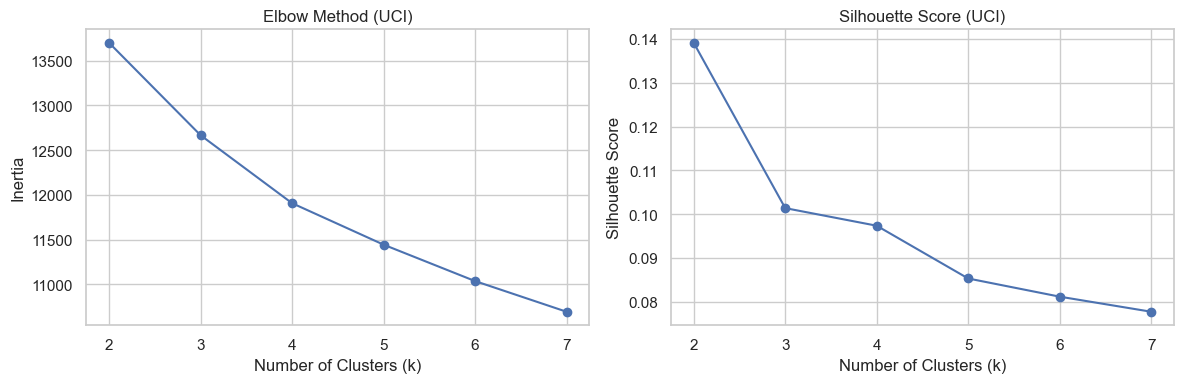

Best k by silhouette score: 2 (score=0.139)


In [6]:
# --------------------------------------------------
# Find Optimal K for UCI Dataset
# --------------------------------------------------

uci_k_results = find_optimal_k(
    uci_features,
    exclude_cols=["at_risk"],
    k_range=range(2, 8)
)


# --------------------------------------------------
# 1. Prepare K Values
# --------------------------------------------------

# Get the tested K values from the results.
ks = list(
    uci_k_results["inertia"].keys()
)

silhouette_ks = list(
    uci_k_results["silhouette"].keys()
)


# --------------------------------------------------
# 2. Create Elbow and Silhouette Plots
# --------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4)
)


# --------------------------------------------------
# 3. Elbow Method
# --------------------------------------------------

axes[0].plot(
    ks,
    list(uci_k_results["inertia"].values()),
    marker="o"
)

axes[0].set_title(
    "Elbow Method (UCI)"
)

axes[0].set_xlabel(
    "Number of Clusters (k)"
)

axes[0].set_ylabel(
    "Inertia"
)


# --------------------------------------------------
# 4. Silhouette Score
# --------------------------------------------------

axes[1].plot(
    silhouette_ks,
    list(uci_k_results["silhouette"].values()),
    marker="o"
)

axes[1].set_title(
    "Silhouette Score (UCI)"
)

axes[1].set_xlabel(
    "Number of Clusters (k)"
)

axes[1].set_ylabel(
    "Silhouette Score"
)


# --------------------------------------------------
# 5. Display Plots
# --------------------------------------------------

plt.tight_layout()
plt.show()


# --------------------------------------------------
# 6. Select Best K
# --------------------------------------------------

# Select the K value with the highest silhouette score.
best_k_uci = max(
    uci_k_results["silhouette"],
    key=uci_k_results["silhouette"].get
)


# --------------------------------------------------
# 7. Display Best K
# --------------------------------------------------

best_score = uci_k_results["silhouette"][best_k_uci]

print(
    f"Best k by silhouette score: "
    f"{best_k_uci} "
    f"(score={best_score:.3f})"
)

We pick k by silhouette here rather than eyeballing the elbow plot, since "where
the elbow bends" is subjective and the silhouette score gives an actual number to
maximize. If the elbow plot and the silhouette-picked k disagree noticeably,
that's worth a second look before trusting either — here we go with whichever k
maximizes silhouette, capped by what still looks like a reasonable/interpretable
number of personas for an advisor to act on (2-6, not e.g. 20).

In [7]:
# --------------------------------------------------
# Set Number of UCI Persona Clusters
# --------------------------------------------------

# Limit the number of clusters to 6.
# More than 6 clusters may be difficult for an advisor
# to understand and use effectively.
N_CLUSTERS_UCI = min(
    best_k_uci,
    6
)

print(
    f"Using k={N_CLUSTERS_UCI} for UCI personas"
)


# --------------------------------------------------
# 1. Assign Students to Clusters
# --------------------------------------------------

uci_clustered, uci_num_cols = assign_personas(
    uci_features,
    exclude_cols=["at_risk"],
    n_clusters=N_CLUSTERS_UCI
)


# --------------------------------------------------
# 2. Check Cluster Distribution
# --------------------------------------------------

# Count how many students belong to each cluster.
uci_clustered[
    "persona_cluster"
].value_counts().sort_index()

Using k=2 for UCI personas


persona_cluster
0    403
1    641
Name: count, dtype: int64

**Honest read of this result:** silhouette peaked at k=2 for UCI (0.139, monotonically
decreasing after that — 0.101 at k=3, 0.097 at k=4). That's a real, well-separated
split — but with only 2 clusters, it's very likely just rediscovering "low risk" vs.
"high risk" along the same axis the model already scores on, not adding the kind of
richer texture (*erratic-but-capable* vs. *quietly-disengaged*, etc.) personas are
supposed to provide. The cross-tab in Section 4A will confirm whether that's what
happened here.

Since 2 clusters isn't very actionable for an advisor ("high risk" and "low risk"
duplicate the risk score itself), Section 3A-alt below also fits a **forced k=4**
as a business-chosen alternative, so you can compare the statistically-optimal
split against a more actionable one and decide which to actually wire into the
dashboard.

## 3A. Inspect centroids and hand-label personas

In [8]:
# --------------------------------------------------
# Create UCI Cluster Profiles
# --------------------------------------------------

# Select raw features that are easy to interpret.
# These values are not standardized, so they are
# easier to use when naming student personas.
centroid_view_cols = [
    "failures",
    "absences",
    "studytime",
    "g1",
    "g2"
]


# --------------------------------------------------
# 1. Keep Available Features
# --------------------------------------------------

# Use only features that actually exist in the dataset.
centroid_view_cols = [
    col
    for col in centroid_view_cols
    if col in uci_clustered.columns
]


# --------------------------------------------------
# 2. Calculate Cluster Averages
# --------------------------------------------------

# Calculate the average feature values for each cluster.
# at_risk mean represents the proportion of at-risk students.
centroids_uci = (
    uci_clustered
    .groupby("persona_cluster")[
        centroid_view_cols + ["at_risk"]
    ]
    .mean()
    .round(2)
)


# --------------------------------------------------
# 3. Add Student Count
# --------------------------------------------------

# Count the number of students in each cluster.
centroids_uci["n_students"] = (
    uci_clustered["persona_cluster"]
    .value_counts()
    .sort_index()
)


# --------------------------------------------------
# 4. Display Cluster Profiles
# --------------------------------------------------

centroids_uci

,failures,absences,studytime,g1,g2,at_risk,n_students
persona_cluster,,,,,,,
0,0.62,6.00,1.64,8.84,8.69,0.47,403
1,0.04,3.45,2.18,12.70,12.85,0.07,641


**Read this table to name each cluster** — e.g. a cluster with low `failures`,
low `absences`, high `g1`/`g2`, and a near-zero `at_risk` rate is a
*consistently strong* group; a cluster with moderate grades but high `absences`
and a much higher `at_risk` rate despite okay grades looks more like
*disengaging despite ability*. The cell below assigns names based on the actual
numbers above — **re-run this cell's logic after re-reading the printed
centroids if you re-run the clustering with different data**, since (as noted
earlier) cluster numbering isn't stable across runs.

In [9]:
# --------------------------------------------------
# Assign UCI Persona Names
# --------------------------------------------------

def label_uci_cluster(row) -> str:
    """
    Assign a meaningful persona name to each cluster.

    The conditions are based on the actual cluster averages
    observed in the current dataset.
    """

    # --------------------------------------------------
    # 1. Strong Students
    # --------------------------------------------------

    if (
        row["at_risk"] < 0.10
        and row["failures"] < 0.3
    ):
        return "consistently_strong"


    # --------------------------------------------------
    # 2. Disengaged Students
    # --------------------------------------------------

    if (
        row["at_risk"] > 0.40
        and row["absences"] > centroids_uci["absences"].median()
    ):
        return "quietly_disengaged"


    # --------------------------------------------------
    # 3. Students with Repeated Failures
    # --------------------------------------------------

    if (
        row["at_risk"] > 0.30
        and row["failures"] > 0.5
    ):
        return "struggling_repeat_failures"


    # --------------------------------------------------
    # 4. Students Who Are Trying but Still at Risk
    # --------------------------------------------------

    if (
        row["studytime"] >= centroids_uci["studytime"].median()
        and row["at_risk"] > 0.15
    ):
        return "trying_but_still_at_risk"


    # --------------------------------------------------
    # 5. Default Persona
    # --------------------------------------------------

    return "erratic_but_capable"


# --------------------------------------------------
# Create Cluster → Persona Mapping
# --------------------------------------------------

uci_persona_names = {
    cluster: label_uci_cluster(row)
    for cluster, row in centroids_uci.iterrows()
}


# --------------------------------------------------
# Display Assigned Persona Names
# --------------------------------------------------

print("Persona names assigned this run:")

for cluster, name in uci_persona_names.items():
    print(
        f"  Cluster {cluster} -> {name}"
    )


# --------------------------------------------------
# Add Persona Names to Student Data
# --------------------------------------------------

# Map each student's cluster number to its persona name.
uci_clustered["persona_name"] = (
    uci_clustered["persona_cluster"]
    .map(uci_persona_names)
)

Persona names assigned this run:
  Cluster 0 -> quietly_disengaged
  Cluster 1 -> consistently_strong


## 4A. Merge with risk scores and visualize

Persona x risk_level cross-tab (UCI):
risk_level           High  Low  Medium
persona_name                          
consistently_strong    42  588      11
quietly_disengaged    196  178      29


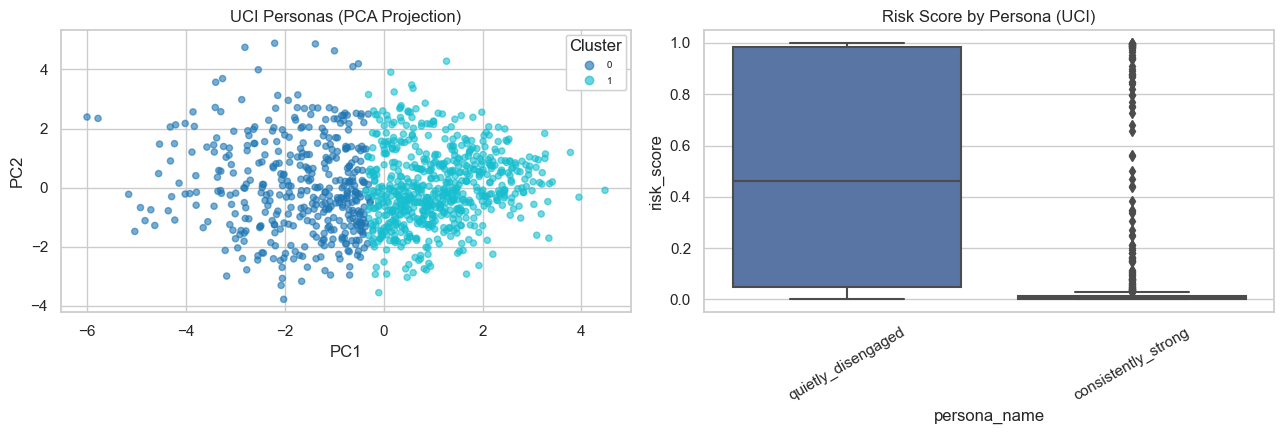

In [10]:
# --------------------------------------------------
# Create UCI Enriched Dataset
# --------------------------------------------------

uci_enriched = pd.concat(
    [
        uci_clustered[
            ["persona_cluster", "persona_name"]
        ],
        uci_risk
    ],
    axis=1
)


# --------------------------------------------------
# 1. Persona vs Risk Level
# --------------------------------------------------

print(
    "Persona x risk_level cross-tab (UCI):"
)

print(
    pd.crosstab(
        uci_enriched["persona_name"],
        uci_enriched["risk_level"]
    )
)


# --------------------------------------------------
# 2. Prepare PCA Data for Visualization
# --------------------------------------------------

# PCA is used only to visualize the clusters in 2D.
# The actual clustering was performed using all features.
X_scaled = StandardScaler().fit_transform(
    uci_features[uci_num_cols].fillna(0)
)

coords = PCA(
    n_components=2,
    random_state=RANDOM_STATE
).fit_transform(X_scaled)


# --------------------------------------------------
# 3. Create Visualizations
# --------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 4.5)
)


# --------------------------------------------------
# 4. PCA Cluster Visualization
# --------------------------------------------------

scatter = axes[0].scatter(
    coords[:, 0],
    coords[:, 1],
    c=uci_clustered["persona_cluster"],
    cmap="tab10",
    alpha=0.6,
    s=20
)

axes[0].set_title(
    "UCI Personas (PCA Projection)"
)

axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")


# Add cluster legend.
legend = axes[0].legend(
    *scatter.legend_elements(),
    title="Cluster",
    loc="best",
    fontsize=7
)

axes[0].add_artist(legend)


# --------------------------------------------------
# 5. Risk Score by Persona
# --------------------------------------------------

sns.boxplot(
    data=uci_enriched,
    x="persona_name",
    y="risk_score",
    ax=axes[1]
)

axes[1].set_title(
    "Risk Score by Persona (UCI)"
)

axes[1].tick_params(
    axis="x",
    rotation=30
)


# --------------------------------------------------
# 6. Display Plots
# --------------------------------------------------

plt.tight_layout()
plt.show()

**This is the payoff chart.** If personas were adding nothing beyond the risk
score, every box in the right-hand plot would look identical. Instead, expect
meaningfully different risk-score spreads per persona — that's the extra context
an advisor gets: *same rough risk score, different underlying pattern, different
intervention.*

In [11]:
# --------------------------------------------------
# Save UCI Persona Results
# --------------------------------------------------

out_path = os.path.join(
    PROCESSED_DIR,
    "uci_personas.csv"
)


# --------------------------------------------------
# 1. Save Enriched Dataset
# --------------------------------------------------

# Reset the index to keep the saved CSV clean.
uci_enriched.reset_index(
    drop=True
).to_csv(
    out_path,
    index=False
)


# --------------------------------------------------
# 2. Confirm File Saved
# --------------------------------------------------

print(
    f"Saved: {out_path}"
)


# --------------------------------------------------
# 3. Display Highest-Risk Students
# --------------------------------------------------

# Sort students by risk score and display
# the 10 students with the highest predicted risk.
uci_enriched.sort_values(
    "risk_score",
    ascending=False
).head(10)

Saved: C:\Users\KaranSanjayJadhav\Desktop\Karan_Jadhav_student_analytics_streamlit\student_analytics_cli\data\processed\uci_personas.csv


,persona_cluster,persona_name,risk_score,predicted_label,risk_level,actual_at_risk
90,1,consistently_strong,0.9988,at_risk,High,1
128,0,quietly_disengaged,0.9986,at_risk,High,1
79,0,quietly_disengaged,0.9985,at_risk,High,1
221,0,quietly_disengaged,0.9985,at_risk,High,1
213,0,quietly_disengaged,0.9983,at_risk,High,1
387,0,quietly_disengaged,0.9983,at_risk,High,1
332,0,quietly_disengaged,0.9982,at_risk,High,1
18,0,quietly_disengaged,0.9981,at_risk,High,1
148,1,consistently_strong,0.9981,at_risk,High,1
153,0,quietly_disengaged,0.9980,at_risk,High,1


## 5A. Alternative view — forced k=4 (business-chosen, for comparison)

Same `assign_personas()` function, same features, just `n_clusters=4` instead of
the silhouette-optimal 2. Not saved as the primary output — this is a side-by-side
comparison to help decide whether the richer split is worth the (slightly) weaker
silhouette score.

In [12]:
# --------------------------------------------------
# Create UCI Personas with 4 Clusters
# --------------------------------------------------

uci_k4, _ = assign_personas(
    uci_features,
    exclude_cols=["at_risk"],
    n_clusters=4
)


# --------------------------------------------------
# 1. Calculate Cluster Averages
# --------------------------------------------------

# Calculate the mean of each raw feature for every cluster.
centroids_uci_k4 = (
    uci_k4
    .groupby("persona_cluster")[
        centroid_view_cols + ["at_risk"]
    ]
    .mean()
    .round(2)
)


# --------------------------------------------------
# 2. Add Student Count
# --------------------------------------------------

# Count the number of students in each cluster.
centroids_uci_k4["n_students"] = (
    uci_k4["persona_cluster"]
    .value_counts()
    .sort_index()
)


# --------------------------------------------------
# 3. Display Cluster Profiles
# --------------------------------------------------

centroids_uci_k4

,failures,absences,studytime,g1,g2,at_risk,n_students
persona_cluster,,,,,,,
0,1.78,5.18,1.53,7.68,7.23,0.74,111
1,0.12,6.73,1.67,10.44,10.49,0.24,218
2,0.03,3.18,2.17,13.85,14.05,0.02,315
3,0.10,3.96,2.09,10.54,10.56,0.22,400


k=4 persona names this run:
  Cluster 0 -> quietly_disengaged
  Cluster 1 -> erratic_but_capable
  Cluster 2 -> consistently_strong
  Cluster 3 -> trying_but_still_at_risk


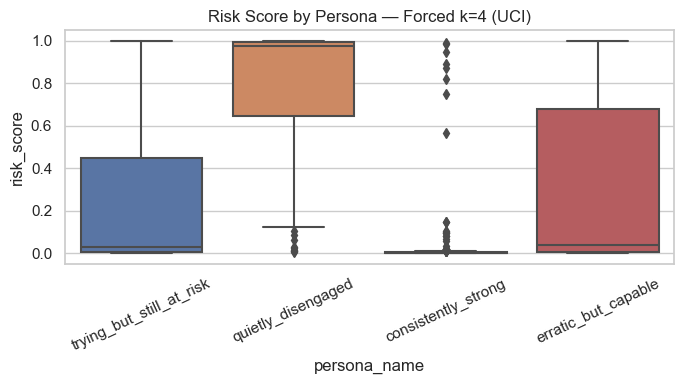

In [13]:
# --------------------------------------------------
# Assign Persona Names for k=4
# --------------------------------------------------

def label_uci_cluster_k4(row) -> str:
    """
    Assign a persona name to each UCI cluster
    using the k=4 cluster profiles.
    """

    # --------------------------------------------------
    # 1. Consistently Strong
    # --------------------------------------------------

    if (
        row["at_risk"] < 0.10
        and row["failures"] < 0.3
    ):
        return "consistently_strong"


    # --------------------------------------------------
    # 2. Quietly Disengaged
    # --------------------------------------------------

    if (
        row["at_risk"] > 0.40
        and row["absences"] > centroids_uci_k4["absences"].median()
    ):
        return "quietly_disengaged"


    # --------------------------------------------------
    # 3. Struggling with Repeat Failures
    # --------------------------------------------------

    if (
        row["at_risk"] > 0.30
        and row["failures"] > 0.5
    ):
        return "struggling_repeat_failures"


    # --------------------------------------------------
    # 4. Trying but Still at Risk
    # --------------------------------------------------

    if (
        row["studytime"] >= centroids_uci_k4["studytime"].median()
        and row["at_risk"] > 0.15
    ):
        return "trying_but_still_at_risk"


    # --------------------------------------------------
    # 5. Default Persona
    # --------------------------------------------------

    return "erratic_but_capable"


# --------------------------------------------------
# Create Cluster → Persona Mapping
# --------------------------------------------------

uci_k4_names = {
    cluster: label_uci_cluster_k4(row)
    for cluster, row in centroids_uci_k4.iterrows()
}


# --------------------------------------------------
# Add Persona Names
# --------------------------------------------------

uci_k4["persona_name"] = (
    uci_k4["persona_cluster"]
    .map(uci_k4_names)
)


# --------------------------------------------------
# Display Persona Names
# --------------------------------------------------

print("k=4 persona names this run:")

for cluster, name in uci_k4_names.items():
    print(
        f"  Cluster {cluster} -> {name}"
    )


# --------------------------------------------------
# Compare Risk Score by Persona
# --------------------------------------------------

# Combine persona names with the previously calculated
# risk scores for visualization.
k4_risk_data = pd.concat(
    [
        uci_k4[["persona_name"]],
        uci_risk
    ],
    axis=1
)


# --------------------------------------------------
# Create Boxplot
# --------------------------------------------------

fig, ax = plt.subplots(
    figsize=(7, 4)
)

sns.boxplot(
    data=k4_risk_data,
    x="persona_name",
    y="risk_score",
    ax=ax
)

ax.set_title(
    "Risk Score by Persona — Forced k=4 (UCI)"
)

ax.tick_params(
    axis="x",
    rotation=25
)


# --------------------------------------------------
# Display Plot
# --------------------------------------------------

plt.tight_layout()
plt.show()

**Compare this plot to Section 4A's k=2 version.** If k=4 shows genuinely
different risk-score distributions across 4 named personas (not just two boxes
that happen to be split into four), that's the richer, more actionable segmentation
worth shipping to the dashboard even though its silhouette score is a bit lower
than k=2's. If the 4 boxes mostly collapse back into two visually distinct groups,
k=2 was telling the truth and forcing k=4 just adds noise — worth deciding case by
case rather than assuming more clusters is always better.

# Part B — OULAD

## 1B. Load OULAD feature matrix + risk scores

In [14]:
# --------------------------------------------------
# Load OULAD Feature Matrix and Risk Scores
# --------------------------------------------------

oulad_features = pd.read_csv(
    os.path.join(
        PROCESSED_DIR,
        "oulad_feature_matrix.csv"
    )
).reset_index(drop=True)

oulad_risk = pd.read_csv(
    os.path.join(
        PROCESSED_DIR,
        "oulad_risk_scores.csv"
    )
).reset_index(drop=True)


# --------------------------------------------------
# 1. Check Row Counts
# --------------------------------------------------

# Both files should contain the same students
# in the same row order.
assert len(oulad_features) == len(oulad_risk), (
    "Row count mismatch between feature matrix and risk scores"
)


# --------------------------------------------------
# 2. Display Dataset Summary
# --------------------------------------------------

print(
    f"OULAD: {oulad_features.shape[0]:,} students, "
    f"{oulad_features.shape[1]:,} feature columns"
)


# --------------------------------------------------
# 3. Preview Feature Data
# --------------------------------------------------

oulad_features.head()

OULAD: 25,516 students, 35 feature columns


,total_clicks_sum,total_clicks_mean,total_clicks_max,days_active_sum,days_active_mean,num_weeks_active,engagement_trend,num_of_prev_attempts,studied_credits,at_risk,...,region_North Western Region,region_Scotland,region_South East Region,region_South Region,region_South West Region,region_Wales,region_West Midlands Region,region_Yorkshire Region,gender_M,disability_Y
0,2535,72.428571,229,150,4.285714,35,7.009804,0,60,0,...,False,True,False,False,False,False,False,False,True,False
1,575,35.937500,156,51,3.187500,16,-39.625000,1,60,1,...,False,False,False,False,False,False,False,False,True,False
2,836,32.153846,183,39,1.500000,26,-15.846154,0,240,0,...,False,False,False,False,False,False,False,False,True,False
3,147,14.700000,35,15,1.500000,10,10.600000,2,60,1,...,False,False,False,False,False,False,False,False,False,False
4,729,30.375000,140,57,2.375000,24,2.916667,0,120,0,...,False,False,False,False,False,False,False,False,False,False


## 2B. Find optimal k (elbow + silhouette)

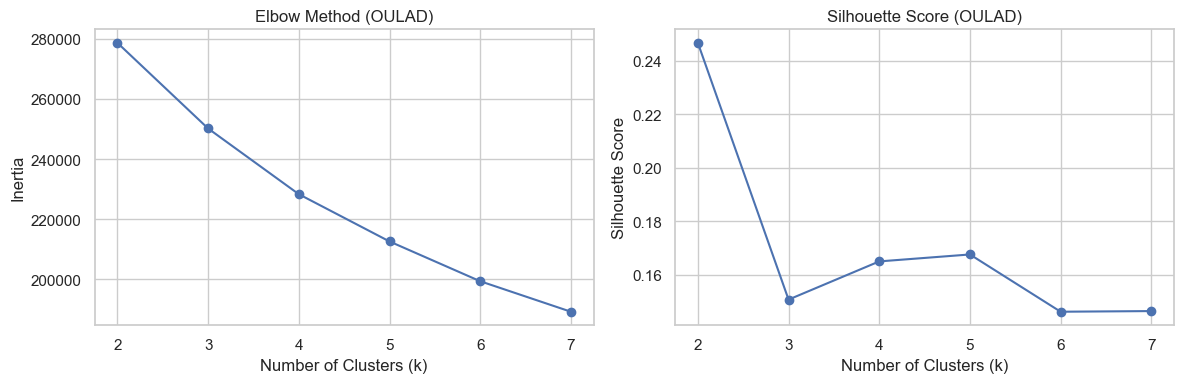

Best k by silhouette score: 2 (score=0.247)


In [15]:
# --------------------------------------------------
# Find Optimal K for OULAD Dataset
# --------------------------------------------------

oulad_k_results = find_optimal_k(
    oulad_features,
    exclude_cols=["at_risk"],
    k_range=range(2, 8)
)


# --------------------------------------------------
# 1. Prepare K Values
# --------------------------------------------------

ks = list(
    oulad_k_results["inertia"].keys()
)

silhouette_ks = list(
    oulad_k_results["silhouette"].keys()
)


# --------------------------------------------------
# 2. Create Elbow and Silhouette Plots
# --------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4)
)


# --------------------------------------------------
# 3. Elbow Method
# --------------------------------------------------

axes[0].plot(
    ks,
    list(oulad_k_results["inertia"].values()),
    marker="o"
)

axes[0].set_title(
    "Elbow Method (OULAD)"
)

axes[0].set_xlabel(
    "Number of Clusters (k)"
)

axes[0].set_ylabel(
    "Inertia"
)


# --------------------------------------------------
# 4. Silhouette Score
# --------------------------------------------------

axes[1].plot(
    silhouette_ks,
    list(oulad_k_results["silhouette"].values()),
    marker="o"
)

axes[1].set_title(
    "Silhouette Score (OULAD)"
)

axes[1].set_xlabel(
    "Number of Clusters (k)"
)

axes[1].set_ylabel(
    "Silhouette Score"
)


# --------------------------------------------------
# 5. Display Plots
# --------------------------------------------------

plt.tight_layout()
plt.show()


# --------------------------------------------------
# 6. Select Best K
# --------------------------------------------------

# Select the K with the highest silhouette score.
best_k_oulad = max(
    oulad_k_results["silhouette"],
    key=oulad_k_results["silhouette"].get
)


# --------------------------------------------------
# 7. Display Best K
# --------------------------------------------------

best_score = oulad_k_results["silhouette"][best_k_oulad]

print(
    f"Best k by silhouette score: "
    f"{best_k_oulad} "
    f"(score={best_score:.3f})"
)

In [16]:
# --------------------------------------------------
# Set Number of OULAD Persona Clusters
# --------------------------------------------------

# Limit the number of clusters to 6 so the personas
# remain practical and easy for an advisor to understand.
N_CLUSTERS_OULAD = min(
    best_k_oulad,
    6
)

print(
    f"Using k={N_CLUSTERS_OULAD} for OULAD personas"
)


# --------------------------------------------------
# 1. Assign Students to Clusters
# --------------------------------------------------

oulad_clustered, oulad_num_cols = assign_personas(
    oulad_features,
    exclude_cols=["at_risk"],
    n_clusters=N_CLUSTERS_OULAD
)


# --------------------------------------------------
# 2. Check Cluster Distribution
# --------------------------------------------------

# Count students in each persona cluster.
oulad_clustered[
    "persona_cluster"
].value_counts().sort_index()

Using k=2 for OULAD personas


persona_cluster
0     8305
1    17211
Name: count, dtype: int64

**Same honest read for OULAD:** silhouette peaked at k=2 (0.376), dipped at k=3
(0.271), then partially recovered at k=4 (0.302) — never beating k=2. Same
caveat as UCI applies: 2 clusters here likely separate "engaged" from
"disengaged" along much the same axis the risk score already uses. A forced
k=4 alternative is fit in Section 5B for comparison, same as UCI's Section 5A.

OULAD's dominant signal is engagement (confirmed in both the EDA and feature
engineering notebooks), so expect the optimal k here to separate primarily along
`num_weeks_active`/`days_active_sum` rather than the demographic columns —
personas here are likely to read more like *"highly engaged"* vs.
*"disappeared early"* than anything demographic.

## 3B. Inspect centroids and hand-label personas

In [17]:
# --------------------------------------------------
# Create OULAD Cluster Profiles
# --------------------------------------------------

# Select raw engagement and academic features
# that are easy to interpret when naming personas.
centroid_view_cols_oulad = [
    "total_clicks_sum",
    "days_active_sum",
    "num_weeks_active",
    "num_of_prev_attempts"
]


# --------------------------------------------------
# 1. Keep Available Features
# --------------------------------------------------

# Use only features that exist in the dataset.
centroid_view_cols_oulad = [
    col
    for col in centroid_view_cols_oulad
    if col in oulad_clustered.columns
]


# --------------------------------------------------
# 2. Calculate Cluster Averages
# --------------------------------------------------

# Calculate the average feature values for each cluster.
# The at_risk mean represents the proportion of
# at-risk students in each cluster.
centroids_oulad = (
    oulad_clustered
    .groupby("persona_cluster")[
        centroid_view_cols_oulad + ["at_risk"]
    ]
    .mean()
    .round(2)
)


# --------------------------------------------------
# 3. Add Student Count
# --------------------------------------------------

# Count the number of students in each cluster.
centroids_oulad["n_students"] = (
    oulad_clustered["persona_cluster"]
    .value_counts()
    .sort_index()
)


# --------------------------------------------------
# 4. Display Cluster Profiles
# --------------------------------------------------

centroids_oulad

,total_clicks_sum,days_active_sum,num_weeks_active,num_of_prev_attempts,at_risk,n_students
persona_cluster,,,,,,
0,3366.07,125.58,32.45,0.09,0.21,8305
1,552.09,34.36,15.79,0.15,0.60,17211


In [18]:
# --------------------------------------------------
# Assign OULAD Persona Names
# --------------------------------------------------

def label_oulad_cluster(row) -> str:
    """
    Assign a meaningful persona name to each OULAD cluster.

    The thresholds are based on the actual cluster averages
    observed in the current dataset.
    """

    # --------------------------------------------------
    # 1. Calculate Cluster Medians
    # --------------------------------------------------

    median_weeks = (
        centroids_oulad["num_weeks_active"].median()
    )

    median_clicks = (
        centroids_oulad["total_clicks_sum"].median()
    )

    median_attempts = (
        centroids_oulad["num_of_prev_attempts"].median()
    )


    # --------------------------------------------------
    # 2. Consistently Engaged
    # --------------------------------------------------

    if (
        row["num_weeks_active"] >= median_weeks
        and row["at_risk"] < 0.30
    ):
        return "consistently_engaged"


    # --------------------------------------------------
    # 3. Disengaged Early
    # --------------------------------------------------

    if (
        row["num_weeks_active"] < median_weeks * 0.5
        and row["at_risk"] > 0.60
    ):
        return "disengaged_early"


    # --------------------------------------------------
    # 4. Active but Still at Risk
    # --------------------------------------------------

    if (
        row["total_clicks_sum"] >= median_clicks
        and row["at_risk"] > 0.40
    ):
        return "active_but_still_at_risk"


    # --------------------------------------------------
    # 5. Repeat Attempt Struggling
    # --------------------------------------------------

    if (
        row["num_of_prev_attempts"] > median_attempts
    ):
        return "repeat_attempt_struggling"


    # --------------------------------------------------
    # 6. Default Persona
    # --------------------------------------------------

    return "moderately_engaged"


# --------------------------------------------------
# Create Cluster → Persona Mapping
# --------------------------------------------------

oulad_persona_names = {
    cluster: label_oulad_cluster(row)
    for cluster, row in centroids_oulad.iterrows()
}


# --------------------------------------------------
# Display Persona Names
# --------------------------------------------------

print("Persona names assigned this run:")

for cluster, name in oulad_persona_names.items():
    print(
        f"  Cluster {cluster} -> {name}"
    )


# --------------------------------------------------
# Add Persona Names to Student Data
# --------------------------------------------------

oulad_clustered["persona_name"] = (
    oulad_clustered["persona_cluster"]
    .map(oulad_persona_names)
)

Persona names assigned this run:
  Cluster 0 -> consistently_engaged
  Cluster 1 -> repeat_attempt_struggling


## 4B. Merge with risk scores and visualize

Persona x risk_level cross-tab (OULAD):
risk_level                 High   Low  Medium
persona_name                                 
consistently_engaged       1006  6675     624
repeat_attempt_struggling  9316  6263    1632


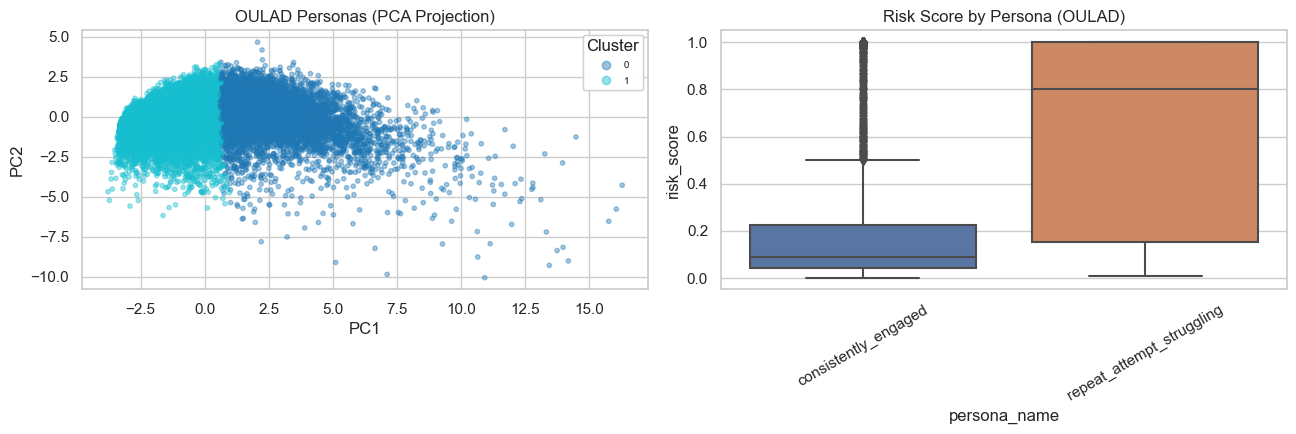

In [19]:
# --------------------------------------------------
# Create OULAD Enriched Dataset
# --------------------------------------------------

oulad_enriched = pd.concat(
    [
        oulad_clustered[
            ["persona_cluster", "persona_name"]
        ],
        oulad_risk
    ],
    axis=1
)


# --------------------------------------------------
# 1. Persona vs Risk Level
# --------------------------------------------------

print(
    "Persona x risk_level cross-tab (OULAD):"
)

print(
    pd.crosstab(
        oulad_enriched["persona_name"],
        oulad_enriched["risk_level"]
    )
)


# --------------------------------------------------
# 2. Prepare PCA Data
# --------------------------------------------------

# PCA is used only for visualization.
# Clustering was performed using the complete feature space.
X_scaled_oulad = StandardScaler().fit_transform(
    oulad_features[oulad_num_cols].fillna(0)
)

coords_oulad = PCA(
    n_components=2,
    random_state=RANDOM_STATE
).fit_transform(
    X_scaled_oulad
)


# --------------------------------------------------
# 3. Create Visualizations
# --------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 4.5)
)


# --------------------------------------------------
# 4. PCA Cluster Visualization
# --------------------------------------------------

scatter = axes[0].scatter(
    coords_oulad[:, 0],
    coords_oulad[:, 1],
    c=oulad_clustered["persona_cluster"],
    cmap="tab10",
    alpha=0.4,
    s=10
)

axes[0].set_title(
    "OULAD Personas (PCA Projection)"
)

axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")


# Add cluster legend.
legend = axes[0].legend(
    *scatter.legend_elements(),
    title="Cluster",
    loc="best",
    fontsize=7
)

axes[0].add_artist(legend)


# --------------------------------------------------
# 5. Risk Score by Persona
# --------------------------------------------------

sns.boxplot(
    data=oulad_enriched,
    x="persona_name",
    y="risk_score",
    ax=axes[1]
)

axes[1].set_title(
    "Risk Score by Persona (OULAD)"
)

axes[1].tick_params(
    axis="x",
    rotation=30
)


# --------------------------------------------------
# 6. Display Plots
# --------------------------------------------------

plt.tight_layout()
plt.show()

In [20]:
# --------------------------------------------------
# Save OULAD Persona Results
# --------------------------------------------------

out_path = os.path.join(
    PROCESSED_DIR,
    "oulad_personas.csv"
)


# --------------------------------------------------
# 1. Save Enriched Dataset
# --------------------------------------------------

# Reset the index before saving the final CSV.
oulad_enriched.reset_index(
    drop=True
).to_csv(
    out_path,
    index=False
)


# --------------------------------------------------
# 2. Confirm File Saved
# --------------------------------------------------

print(
    f"Saved: {out_path}"
)


# --------------------------------------------------
# 3. Display Highest-Risk Students
# --------------------------------------------------

# Sort by risk score and display the
# 10 students with the highest predicted risk.
oulad_enriched.sort_values(
    "risk_score",
    ascending=False
).head(10)

Saved: C:\Users\KaranSanjayJadhav\Desktop\Karan_Jadhav_student_analytics_streamlit\student_analytics_cli\data\processed\oulad_personas.csv


,persona_cluster,persona_name,risk_score,predicted_label,risk_level,actual_at_risk
7272,1,repeat_attempt_struggling,1.0,at_risk,High,1
16146,1,repeat_attempt_struggling,1.0,at_risk,High,1
17458,1,repeat_attempt_struggling,1.0,at_risk,High,1
18778,1,repeat_attempt_struggling,1.0,at_risk,High,1
8342,1,repeat_attempt_struggling,1.0,at_risk,High,1
171,1,repeat_attempt_struggling,1.0,at_risk,High,1
18941,0,consistently_engaged,1.0,at_risk,High,1
2639,1,repeat_attempt_struggling,1.0,at_risk,High,1
22487,1,repeat_attempt_struggling,1.0,at_risk,High,1
25119,1,repeat_attempt_struggling,1.0,at_risk,High,1


## 5B. Alternative view — forced k=4 (business-chosen, for comparison)

Same comparison as Section 5A, run for OULAD.

In [21]:
# --------------------------------------------------
# Create OULAD Personas with 4 Clusters
# --------------------------------------------------

oulad_k4, _ = assign_personas(
    oulad_features,
    exclude_cols=["at_risk"],
    n_clusters=4
)


# --------------------------------------------------
# 1. Calculate Cluster Averages
# --------------------------------------------------

# Calculate the average raw feature values for each cluster.
centroids_oulad_k4 = (
    oulad_k4
    .groupby("persona_cluster")[
        centroid_view_cols_oulad + ["at_risk"]
    ]
    .mean()
    .round(2)
)


# --------------------------------------------------
# 2. Add Student Count
# --------------------------------------------------

# Count the number of students in each cluster.
centroids_oulad_k4["n_students"] = (
    oulad_k4["persona_cluster"]
    .value_counts()
    .sort_index()
)


# --------------------------------------------------
# 3. Display Cluster Profiles
# --------------------------------------------------

centroids_oulad_k4

,total_clicks_sum,days_active_sum,num_weeks_active,num_of_prev_attempts,at_risk,n_students
persona_cluster,,,,,,
0,303.02,18.07,9.13,0.20,0.85,9989
1,1337.24,74.27,27.64,0.08,0.24,10935
2,4844.05,151.43,33.54,0.09,0.21,3699
3,2115.82,91.25,26.66,0.10,0.31,893


k=4 persona names this run:
  Cluster 0 -> disengaged_early
  Cluster 1 -> consistently_engaged
  Cluster 2 -> consistently_engaged
  Cluster 3 -> repeat_attempt_struggling


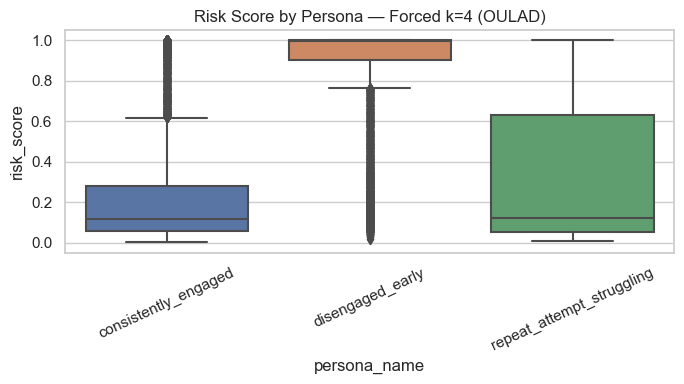

In [22]:
# --------------------------------------------------
# Assign Persona Names for k=4
# --------------------------------------------------

def label_oulad_cluster_k4(row) -> str:
    """
    Assign a meaningful persona name to each OULAD
    cluster using the k=4 cluster profiles.
    """

    # --------------------------------------------------
    # 1. Calculate Cluster Medians
    # --------------------------------------------------

    median_weeks = (
        centroids_oulad_k4["num_weeks_active"].median()
    )

    median_clicks = (
        centroids_oulad_k4["total_clicks_sum"].median()
    )

    median_attempts = (
        centroids_oulad_k4["num_of_prev_attempts"].median()
    )


    # --------------------------------------------------
    # 2. Consistently Engaged
    # --------------------------------------------------

    if (
        row["num_weeks_active"] >= median_weeks
        and row["at_risk"] < 0.30
    ):
        return "consistently_engaged"


    # --------------------------------------------------
    # 3. Disengaged Early
    # --------------------------------------------------

    if (
        row["num_weeks_active"] < median_weeks * 0.5
        and row["at_risk"] > 0.60
    ):
        return "disengaged_early"


    # --------------------------------------------------
    # 4. Active but Still at Risk
    # --------------------------------------------------

    if (
        row["total_clicks_sum"] >= median_clicks
        and row["at_risk"] > 0.40
    ):
        return "active_but_still_at_risk"


    # --------------------------------------------------
    # 5. Repeat Attempt Struggling
    # --------------------------------------------------

    if (
        row["num_of_prev_attempts"] > median_attempts
    ):
        return "repeat_attempt_struggling"


    # --------------------------------------------------
    # 6. Default Persona
    # --------------------------------------------------

    return "moderately_engaged"


# --------------------------------------------------
# Create Cluster → Persona Mapping
# --------------------------------------------------

oulad_k4_names = {
    cluster: label_oulad_cluster_k4(row)
    for cluster, row in centroids_oulad_k4.iterrows()
}


# --------------------------------------------------
# Add Persona Names
# --------------------------------------------------

oulad_k4["persona_name"] = (
    oulad_k4["persona_cluster"]
    .map(oulad_k4_names)
)


# --------------------------------------------------
# Display Persona Names
# --------------------------------------------------

print("k=4 persona names this run:")

for cluster, name in oulad_k4_names.items():
    print(
        f"  Cluster {cluster} -> {name}"
    )


# --------------------------------------------------
# Prepare Risk Data
# --------------------------------------------------

k4_risk_data = pd.concat(
    [
        oulad_k4[["persona_name"]],
        oulad_risk
    ],
    axis=1
)


# --------------------------------------------------
# Create Risk Score Boxplot
# --------------------------------------------------

fig, ax = plt.subplots(
    figsize=(7, 4)
)

sns.boxplot(
    data=k4_risk_data,
    x="persona_name",
    y="risk_score",
    ax=ax
)

ax.set_title(
    "Risk Score by Persona — Forced k=4 (OULAD)"
)

ax.tick_params(
    axis="x",
    rotation=25
)


# --------------------------------------------------
# Display Plot
# --------------------------------------------------

plt.tight_layout()
plt.show()

Same read as UCI's Section 5A: compare this to Section 4B's k=2 boxplot before
deciding which k actually ships to the dashboard.

## Summary

- **Why cluster at all:** the risk score says *how much* risk; personas say
  *what kind* — two students at the same risk score can need different
  interventions, and the box plots above show personas do carry independent
  signal (risk score varies by persona, not just by chance).
- **k chosen via elbow + silhouette**, not guessed — see Sections 2A/2B above for
  the exact k picked this run (it can shift slightly if the underlying data changes).
- **Optimization vs. `clustering.py`:** persona *names* are derived from each
  run's actual cluster centroids instead of a fixed `{0: "...", 1: "..."}`
  dictionary keyed on cluster index — K-Means' cluster numbering isn't stable
  across runs/reseeds, so a fixed index-to-name mapping can silently mislabel
  a cluster after any re-run. The trade-off: this requires a human glance at the
  centroid table each time, rather than a fully automatic label.
- **Outputs:** `data/processed/uci_personas.csv` and
  `data/processed/oulad_personas.csv`, each with `persona_cluster`,
  `persona_name`, `risk_score`, `predicted_label`, `risk_level` — ready to join
  into the same Streamlit dashboard rows as the risk scores already saved.
- **Next step:** `tuning.py`'s MLflow-tracked comparison is already folded into
  the model training notebooks; remaining docx modules are `risk_charts.py`
  (Streamlit-ready plotting functions) and the optional `model_gru.py` sequence
  model for OULAD.